**Can an LLM Read an IMF Programme Review Reliably? A Seychelles Case Study**

I built this notebook around the IMF's December 2024 report on Seychelles (Country Report No. 24/340), which covers the third reviews of its EFF and RSF arrangements. It turns the PDF into checked summaries, indicator JSON, answers with citations and a four-panel dashboard.

Gemini 3.7 Flash does the reading and Gemini 3.8 Flash marks the work, with code checking the numbers as well. The replies are saved in `cache/llm/`, so Runtime > Run all repeats the results without a key.

**Choosing the source**

Four IMF staff reports on Seychelles came out in 2023-2024. I chose 24/340 because it is the most recent.

**0.1 Install packages**

The versions are fixed so the extracted text stays the same.

In [1]:
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pypdf==6.21.4", "tiktoken==0.14.0", "sentence-transformers==5.7.0",
                    "faiss-cpu==1.15.1", "google-genai==2.12.1", "pydantic==2.14.1"], check=True)
from importlib.metadata import version
print({p: version(p) for p in ("pypdf", "tiktoken", "sentence-transformers", "faiss-cpu", "google-genai", "pydantic",
                                "numpy", "pandas", "matplotlib")})

{'pypdf': '6.21.4', 'tiktoken': '0.14.0', 'sentence-transformers': '5.7.0', 'faiss-cpu': '1.15.1', 'google-genai': '2.12.1', 'pydantic': '2.14.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0'}


**0.2 Settings**

Everything that can be changed is in `CONFIG`, and all paths are relative.

In [2]:
import hashlib, json, os, re, time, unicodedata, difflib
from collections import Counter, defaultdict
from pathlib import Path
from typing import List, Literal, Optional

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError
from pypdf import PdfReader
import tiktoken

CONFIG = {
    "country": "Seychelles",
    "report_label": "IMF Country Report No. 24/340 (December 2024)",
    "pdf_filename": "seychelles_cr24340.pdf",
    # Public IMF link, used only if the PDF is not already in data/.
    "pdf_url": "https://www.imf.org/-/media/files/publications/cr/2024/english/1sycea2024002-print-pdf.pdf",
    "repo_url": "",  # set to the GitHub repo URL so Colab can clone data/ and cache/
    # Where live LLM calls go when an answer is not cached:
    #   "gemini_api" - Google Gemini API with GEMINI_API_KEY
    #   "colab_ai"   - Colab's built-in Gemini access (`google.colab.ai`), no key needed; the route
    #                  used to produce the cached answers that ship with the repository
    #   "agy_cli"    - the Antigravity CLI (`agy -p`), signed in with a Google account
    #   "auto"       - gemini_api if a key is set, else colab_ai inside Colab, else agy_cli if `agy` is
    #                  installed, else cache only
    "llm_backend": "auto",
    # Extractor and judge are deliberately different models (dual-LLM design), so the judge is not
    # grading its own writing. The judge is the newer model of the two.
    "colab_ai_models": {"extractor": "google/gemini-3.7-flash", "judge": "google/gemini-3.8-flash"},
    "agy_models": {"extractor": "gemini-3.8-flash-medium", "judge": "gemini-3.8-flash-high"},
    # Gemini API route: the first name that the API lists as available is used.
    "extractor_models": ["gemini-3.8-flash", "gemini-3.5-flash", "gemini-2.5-flash"],
    "judge_models": ["gemini-3.8-pro", "gemini-3.5-pro", "gemini-2.5-pro", "gemini-2.5-flash-lite"],
    "temperature": 0.0,
    "min_seconds_between_calls": 4.0,   # keeps free-tier quotas happy
    "max_retries": 5,
    "chunk_tokens": 450,                 # inside the 300-500 range set in the brief
    "chunk_overlap": 50,
    "summary_word_limit": 100,           # brief: each section summary under 100 words
    "embed_model": "sentence-transformers/all-MiniLM-L6-v2",
    "top_k": 5,                          # baseline RAG depth
    "multi_query_top_k": 8,              # broader context for the Multi-Query extension
    "theme_batch_size": 15,              # chunks per LLM theme-classification call
    "seed": 42,
}

ROOT = Path.cwd()
if IN_COLAB and CONFIG["repo_url"] and not (ROOT / "data").exists():
    subprocess.run(["git", "clone", "-q", CONFIG["repo_url"], "repo"], check=True)
    os.chdir("repo")
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
CACHE_DIR = ROOT / "cache"
OUT_DIR = ROOT / "outputs"
JSON_DIR = OUT_DIR / "json"
FIG_DIR = OUT_DIR / "figures"
for d in (DATA_DIR, CACHE_DIR / "llm", CACHE_DIR / "rag", JSON_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

np.random.seed(CONFIG["seed"])
pd.set_option("display.max_colwidth", 120)
ENC = tiktoken.get_encoding("cl100k_base")


def n_tokens(text: str) -> int:
    return len(ENC.encode(text))


def _json_safe(obj):
    """Missing values become null: bare NaN is not valid JSON and breaks other readers."""
    if isinstance(obj, float) and not np.isfinite(obj):
        return None
    if isinstance(obj, dict):
        return {k: _json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_json_safe(v) for v in obj]
    return obj


def save_json(obj, name: str) -> Path:
    """Write a machine-readable output file under outputs/json/ (strict JSON, NaN written as null)."""
    path = JSON_DIR / name
    text = json.dumps(_json_safe(json.loads(json.dumps(obj, default=str))), indent=2, ensure_ascii=False, allow_nan=False)
    path.write_text(text, encoding="utf-8")
    return path


print("Root:", ROOT)

Root: /content


**0.3 API key**

The key is read from Colab Secrets and is never printed.

In [3]:
def get_api_key() -> Optional[str]:
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("GEMINI_API_KEY")
        except Exception:
            pass
    return os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")


API_KEY = get_api_key()
AGY = __import__("shutil").which("agy")
try:
    from google.colab import ai as colab_ai   # Colab's built-in Gemini access
except ImportError:
    colab_ai = None
BACKEND = CONFIG["llm_backend"]
if BACKEND == "auto":
    BACKEND = ("gemini_api" if API_KEY else "colab_ai" if colab_ai else "agy_cli" if AGY else "cache_only")
print(f"LLM backend: {BACKEND}" + ("" if BACKEND != "cache_only" else " (every answer must come from cache/llm/)"))

LLM backend: colab_ai


**0.4 Model calls**

All calls go through `call_llm`. Replies are saved, so a rerun makes no new calls.

In [4]:
_client = None
_last_call = 0.0
CALL_LOG: List[dict] = []
MODEL_FILE = CACHE_DIR / "resolved_models.json"


def get_client():
    global _client
    if _client is None:
        if not API_KEY:
            raise RuntimeError("A live LLM call is needed but no GEMINI_API_KEY is set and the answer is not cached.")
        from google import genai
        _client = genai.Client(api_key=API_KEY)
    return _client


def resolve_models() -> dict:
    """Pick the extractor and judge model. The choice is stored so cache replays use the same names."""
    if MODEL_FILE.exists():
        return json.loads(MODEL_FILE.read_text())
    if BACKEND in ("colab_ai", "agy_cli"):
        models = CONFIG[f"{BACKEND}_models"]
        MODEL_FILE.write_text(json.dumps(models, indent=2))
        return dict(models)
    if not API_KEY:
        return {"extractor": CONFIG["extractor_models"][0], "judge": CONFIG["judge_models"][0]}
    available = {m.name.split("/")[-1] for m in get_client().models.list()}
    pick = lambda prefs: next((m for m in prefs if m in available), prefs[-1])
    models = {"extractor": pick(CONFIG["extractor_models"]), "judge": pick(CONFIG["judge_models"])}
    if models["judge"] == models["extractor"]:
        raise RuntimeError("Extractor and judge resolved to the same model; edit CONFIG.")
    MODEL_FILE.write_text(json.dumps(models, indent=2))
    return models


MODELS = resolve_models()
EXTRACTOR, JUDGE = MODELS["extractor"], MODELS["judge"]
print(f"Extractor: {EXTRACTOR} | Judge: {JUDGE}")


def _cache_key(model, system, prompt, schema_name, temperature):
    raw = json.dumps([model, system, prompt, schema_name, temperature], ensure_ascii=False)
    return hashlib.sha256(raw.encode("utf-8")).hexdigest()


def inline_schema(schema) -> dict:
    """Pydantic JSON schema with every $ref expanded, for tools that do not follow references."""
    js = schema.model_json_schema()
    defs = js.pop("$defs", {})

    def expand(node):
        if isinstance(node, dict):
            if "$ref" in node:
                return expand(defs[node["$ref"].split("/")[-1]])
            return {k: expand(v) for k, v in node.items()}
        if isinstance(node, list):
            return [expand(v) for v in node]
        return node
    return expand(js)


AGY_WORKDIR = Path(__import__("tempfile").mkdtemp(prefix="agy_empty_"))  # nothing here for the agent to read


def _agy_generate(model, system, prompt, schema):
    """One live call through the Antigravity CLI in print mode. Returns (text, usage dict)."""
    full = ((f"SYSTEM INSTRUCTIONS (follow strictly):\n{system}\n\n" if system else "")
            + "Do not use any tools. Work only from the text in this message.\n\n" + prompt)
    cmd = [AGY, "-p", full, "--model", model, "--output-format", "json", "--sandbox",
           "--disable-slash-commands", "--print-timeout", "600s"]
    if schema is not None:
        cmd += ["--json-schema", json.dumps(inline_schema(schema))]
    for attempt in range(CONFIG["max_retries"]):
        proc = subprocess.run(cmd, cwd=AGY_WORKDIR, capture_output=True, text=True, timeout=700)
        try:
            out = json.loads(proc.stdout)
        except json.JSONDecodeError:
            out = {"status": "BAD_OUTPUT", "response": proc.stdout[-500:] + proc.stderr[-500:]}
        if out.get("status") == "SUCCESS":
            text = json.dumps(out["structured_output"]) if out.get("structured_output") is not None else out["response"]
            u = out.get("usage", {})
            return text, {"prompt_tokens": u.get("input_tokens"), "output_tokens": u.get("output_tokens")}
        err = str(out.get("error") or out.get("response"))[:300]
        if "quota reached" in err.lower():          # a reset days away is not worth retrying
            break
        time.sleep(min(60, 5 * 2 ** attempt))
    raise RuntimeError(f"agy call on {model} failed: {err}")


def _colab_generate(model, system, prompt, schema):
    """One live call through google.colab.ai. It takes only a prompt, so the system text and the JSON
    schema go into the prompt and call_llm_json validates the reply. Temperature cannot be set."""
    full = (f"SYSTEM INSTRUCTIONS (follow strictly):\n{system}\n\n" if system else "") + prompt
    if schema is not None:
        full += ("\n\nReturn ONLY valid JSON (no markdown fences) matching this JSON schema:\n"
                 + json.dumps(inline_schema(schema)))
    for attempt in range(CONFIG["max_retries"]):
        try:
            return colab_ai.generate_text(full, model_name=model), {"prompt_tokens": None, "output_tokens": None}
        except Exception as e:
            err = str(e)[:300]
            time.sleep(min(60, 5 * 2 ** attempt))
    raise RuntimeError(f"colab_ai call on {model} failed: {err}")


def _live_generate(model, system, prompt, schema, temperature):
    """One live call with backoff. Returns (text, usage dict)."""
    if BACKEND == "colab_ai":
        return _colab_generate(model, system, prompt, schema)
    if BACKEND == "agy_cli":
        return _agy_generate(model, system, prompt, schema)
    if BACKEND != "gemini_api":
        raise RuntimeError("A live LLM call is needed but no backend is available and the answer is not cached.")
    global _last_call
    from google.genai import types
    cfg = dict(temperature=temperature, system_instruction=system or None)
    if schema is not None:
        cfg.update(response_mime_type="application/json", response_schema=schema)
    for attempt in range(CONFIG["max_retries"]):
        wait = CONFIG["min_seconds_between_calls"] - (time.time() - _last_call)
        if wait > 0:
            time.sleep(wait)
        try:
            _last_call = time.time()
            resp = get_client().models.generate_content(
                model=model, contents=prompt, config=types.GenerateContentConfig(**cfg))
            um = resp.usage_metadata
            usage = {"prompt_tokens": getattr(um, "prompt_token_count", None),
                     "output_tokens": getattr(um, "candidates_token_count", None)}
            return resp.text or "", usage
        except Exception as e:
            msg = str(e)
            if any(code in msg for code in ("429", "500", "503", "RESOURCE_EXHAUSTED", "UNAVAILABLE")):
                time.sleep(min(60, 5 * 2 ** attempt))
                continue
            raise
    raise RuntimeError(f"Gave up after {CONFIG['max_retries']} retries on {model}")


def call_llm(prompt: str, model: str = None, system: str = "", schema=None,
             temperature: float = None, tag: str = "") -> str:
    model = model or EXTRACTOR
    temperature = CONFIG["temperature"] if temperature is None else temperature
    schema_name = schema.__name__ if schema is not None else None
    key = _cache_key(model, system, prompt, schema_name, temperature)
    path = CACHE_DIR / "llm" / f"{key}.json"
    if path.exists():
        rec = json.loads(path.read_text(encoding="utf-8"))
        CALL_LOG.append({**rec["meta"], "cache_hit": True})
        return rec["text"]
    t0 = time.time()
    try:
        text, usage = _live_generate(model, system, prompt, schema, temperature)
        mode = "schema" if schema is not None else "text"
    except Exception as e:
        if schema is None or "429" in str(e):
            raise
        # Schema rejected by the API: retry in plain JSON mode with the schema spelled out.
        fallback_prompt = (prompt + "\n\nReturn ONLY valid JSON matching this JSON schema:\n"
                           + json.dumps(schema.model_json_schema()))
        text, usage = _live_generate(model, system, fallback_prompt, None, temperature)
        mode = "json_prompt_fallback"
    meta = {"tag": tag, "model": model, "backend": BACKEND, "mode": mode, "latency_s": round(time.time() - t0, 2), **usage}
    path.write_text(json.dumps({"meta": meta, "text": text}, ensure_ascii=False), encoding="utf-8")
    CALL_LOG.append({**meta, "cache_hit": False})
    return text


def parse_json_text(text: str):
    """Tolerant JSON parse: strips markdown fences and grabs the outermost object or array."""
    text = text.strip()
    text = re.sub(r"^```(?:json)?|```$", "", text, flags=re.M).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        m = re.search(r"(\{.*\}|\[.*\])", text, flags=re.S)
        if not m:
            raise
        return json.loads(m.group(1))


def call_llm_json(prompt: str, schema, **kw):
    """Schema-constrained call. Returns a validated Pydantic object."""
    text = call_llm(prompt, schema=schema, **kw)
    try:
        return schema.model_validate(parse_json_text(text))
    except (ValidationError, json.JSONDecodeError) as e:
        # One repair attempt: show the model its own output and the validation error.
        repair = (f"{prompt}\n\nYour previous reply failed validation:\n{str(e)[:800]}\n"
                  f"Previous reply:\n{text[:4000]}\nReturn corrected JSON only.")
        return schema.model_validate(parse_json_text(call_llm(repair, schema=schema, **kw)))

Extractor: google/gemini-3.7-flash | Judge: google/gemini-3.8-flash


**1.1 Load the PDF**

The report is read from `data/`.

In [5]:
def ensure_pdf() -> Path:
    path = DATA_DIR / CONFIG["pdf_filename"]
    if not path.exists() and (ROOT / CONFIG["pdf_filename"]).exists():   # uploaded next to the notebook
        (ROOT / CONFIG["pdf_filename"]).rename(path)
    if path.exists() and path.read_bytes()[:4] == b"%PDF":
        return path
    try:
        import urllib.request
        req = urllib.request.Request(CONFIG["pdf_url"], headers={"User-Agent": "Mozilla/5.0"})
        data = urllib.request.urlopen(req, timeout=60).read()
        if data[:4] == b"%PDF":
            path.write_bytes(data)
            return path
    except Exception as e:
        print("Download failed:", e)
    if IN_COLAB:
        from google.colab import files
        print(f"Please upload {CONFIG['pdf_filename']}")
        up = files.upload()
        path.write_bytes(next(iter(up.values())))
        return path
    raise FileNotFoundError(f"Put the report at {path}")


PDF_PATH = ensure_pdf()
reader = PdfReader(str(PDF_PATH))
raw_pages = [p.extract_text() or "" for p in reader.pages]
print(f"{PDF_PATH.name}: {len(raw_pages)} pages, {sum(len(t) for t in raw_pages):,} raw characters")

seychelles_cr24340.pdf: 103 pages, 326,838 raw characters


**1.2 Clean the text**

This removes repeated headers and footers and repairs broken lines.

In [6]:
CHAR_MAP = {"’": "'", "‘": "'", "“": '"', "”": '"', "–": "-", "—": "-",
            " ": " ", "ﬁ": "fi", "ﬂ": "fl", "•": "-", "": "-"}


def normalise_chars(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)
    for a, b in CHAR_MAP.items():
        text = text.replace(a, b)
    return text


def boilerplate_lines(pages: List[str], edge: int = 3, share: float = 0.25) -> set:
    """Lines that repeat at the top or bottom of many pages (running headers and footers)."""
    counts = Counter()
    for text in pages:
        lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
        edges = set(re.sub(r"\d+", "#", ln) for ln in lines[:edge] + lines[-edge:] if len(ln) < 80)
        counts.update(edges)
    return {ln for ln, c in counts.items() if c / max(len(pages), 1) > share}


ALWAYS_DROP = [r"^©?\s*International Monetary Fund\.? Not for Redistribution$",
               r"^INTERNATIONAL MONETARY FUND\s*\d*$", r"^\d+\s*INTERNATIONAL MONETARY FUND$",
               r"^\d{1,3}$", r".*_{5,}.*\d+\s*$", r".*\.{6,}\s*\d+\s*$"]


def prose_share(lines: List[str]) -> float:
    lines = [ln for ln in lines if ln.strip()]
    if not lines:
        return 0.0
    prose = sum(1 for ln in lines if len(re.findall(r"[A-Za-z]{2,}", ln)) >= 7)
    return prose / len(lines)


def clean_pages(pages: List[str]) -> List[dict]:
    boiler = boilerplate_lines(pages)
    out = []
    for i, text in enumerate(pages, start=1):
        text = normalise_chars(text)
        kept = []
        for ln in text.split("\n"):
            s = ln.strip()
            if re.sub(r"\d+", "#", s) in boiler or any(re.match(p, s) for p in ALWAYS_DROP):
                continue
            kept.append(s)
        out.append({"page": i, "lines": kept, "narrative": prose_share(kept) >= 0.45,
                    "raw_table_text": "\n".join(kept)})
    return out


def is_caps_line(s: str) -> bool:
    """Short upper-case line, the typography IMF reports use for headings."""
    return (4 <= len(s) <= 95 and bool(re.fullmatch(r"[A-Z0-9 ,.'&():;/\-]+", s))
            and sum(c.isalpha() for c in s) >= 5 and sum(c.isdigit() for c in s) <= 4)


PARA_START = re.compile(r"^\d{1,3}\.\s+[A-Z]")  # IMF numbered paragraphs: "12. The authorities ..."
# Mixed-case headings that open the annexes, appendices and the Executive Director's statement.
NAMED_HEADING = re.compile(r"^((Annex|Appendix)\s+[IVXL]+\.?\s+\S.{0,90}|Statement by .{0,80}Executive Director.*)$")


def lines_to_paragraphs(lines: List[str]) -> List[str]:
    """Rebuild paragraphs. pypdf returns no blank lines for these reports, so breaks are inferred:
    a blank line, an upper-case heading line (kept as its own paragraph), or a numbered paragraph
    that follows a sentence end. Wrapped lines are joined and line-end hyphens mended."""
    paras, buf = [], []

    def flush():
        if buf:
            para = ""
            for part in buf:
                para = para[:-1] + part if para.endswith("-") else (para + " " + part if para else part)
            paras.append(re.sub(r"\s{2,}", " ", para).strip())
            buf.clear()

    for s in lines + [""]:
        if not s:
            flush()
        elif is_caps_line(s) or NAMED_HEADING.match(s):
            flush()
            paras.append(s)
        else:
            if PARA_START.match(s) and buf and buf[-1].rstrip().endswith((".", ":", ";")):
                flush()
            buf.append(s)
    return [p for p in paras if p]


pages = clean_pages(raw_pages)
for pg in pages:
    pg["paragraphs"] = lines_to_paragraphs(pg["lines"])

clean_text = "\n\n".join(p for pg in pages for p in pg["paragraphs"])
narrative_pages = [pg["page"] for pg in pages if pg["narrative"]]
clean_stats = {
    "pages": len(pages), "narrative_pages": len(narrative_pages),
    "table_or_figure_pages": len(pages) - len(narrative_pages),
    "raw_chars": sum(len(t) for t in raw_pages), "clean_chars": len(clean_text),
    "clean_words": len(clean_text.split()), "clean_tokens": n_tokens(clean_text),
    "boilerplate_patterns_removed": sorted(boilerplate_lines(raw_pages)),
}
save_json(clean_stats, "cleaning_stats.json")
print(json.dumps({k: v for k, v in clean_stats.items() if k != "boilerplate_patterns_removed"}, indent=2))
print("Detected running headers/footers:", clean_stats["boilerplate_patterns_removed"])

{
  "pages": 103,
  "narrative_pages": 73,
  "table_or_figure_pages": 30,
  "raw_chars": 326838,
  "clean_chars": 309551,
  "clean_words": 47646,
  "clean_tokens": 73183
}
Detected running headers/footers: ['# INTERNATIONAL MONETARY FUND', 'INTERNATIONAL MONETARY FUND #', 'SEYCHELLES', '©International Monetary Fund. Not for Redistribution']


**1.3 Find the sections**

Sections are found from the report's upper-case headings.

In [7]:
NOT_HEADINGS = {"CONTENTS", "FIGURES", "TABLES", "ANNEXES", "BOXES", "APPENDICES",
                "PROJECTIONS", "SOURCES", "NOTES"}


WRAP_WORDS = {"THE", "AND", "OF", "FOR", "UNDER", "TO", "IN", "ON", "WITH", "BY", "A", "AN"}


def is_heading(line: str) -> bool:
    s = line.strip()
    if NAMED_HEADING.match(s):
        return True
    if not is_caps_line(s) or re.search(r"\((LHS|RHS)\)", s):
        return False
    if s in NOT_HEADINGS or s == CONFIG["country"].upper():
        return False
    return len(s.split()) <= 14


HEADING_ALIASES = {"FOR IMMEDIATE RELEASE": "PRESS RELEASE"}  # the press release has no heading of its own
# Section names IMF staff reports use routinely; these are never treated as part of a title block.
STANDARD_HEADINGS = {"EXECUTIVE SUMMARY", "PRESS RELEASE", "CONTEXT", "CONTEXT AND RECENT DEVELOPMENTS",
                     "RECENT DEVELOPMENTS", "OUTLOOK AND RISKS", "PROGRAM PERFORMANCE", "POLICY DISCUSSIONS",
                     "PROGRAM MODALITIES", "STAFF APPRAISAL"}


def is_prose(para: str) -> bool:
    words = para.split()
    return len(words) >= 30 and sum(bool(re.fullmatch(r"[A-Za-z,.;:'()\-]+", w)) for w in words) / len(words) > 0.7


def detect_sections(pages: List[dict], min_words: int = 120) -> List[dict]:
    sections, current, run = [], {"title": "FRONT MATTER", "pages": [], "paragraphs": []}, 0
    for pg in pages:
        for para in pg["paragraphs"]:
            para = HEADING_ALIASES.get(para, para)
            if not pg["narrative"]:
                # Figure and table pages: keep section headings and real prose, skip axis labels and
                # number rows. Annexes are kept whole because the Risk Assessment Matrix is a table.
                strong_heading = NAMED_HEADING.match(para) or (is_heading(para) and len(para.split()) >= 3
                                                               and not re.search(r"\d", para))
                if not (strong_heading or is_prose(para) or current["title"].startswith("Annex I.")):
                    continue
                if is_heading(para) and not strong_heading:
                    continue
            if is_heading(para):
                run = run + 1 if not current["paragraphs"] else 1
                # A heading line that stops on a connector word ("... UNDER THE") wraps onto the next line.
                last_word = current["title"].split()[-1].upper() if current["title"] else ""
                if not current["paragraphs"] and last_word in WRAP_WORDS:
                    current["title"] += " " + para
                    continue
                sections.append(current)
                current = {"title": para, "pages": [pg["page"]], "paragraphs": [],
                           "title_block": run >= 4 and para not in STANDARD_HEADINGS}
            else:
                if current.get("title_block") and not current["paragraphs"]:
                    # Last line of a multi-line document title (cover page, supplement): name the
                    # section after its own opening words instead of the title fragment.
                    current["title"] = f"Opening of document on p.{pg['page']}: " + " ".join(para.split()[:6]) + " ..."
                current["paragraphs"].append(para)
                current.setdefault("units", []).append((para, pg["page"]))  # page of every paragraph, for citations
                if pg["page"] not in current["pages"]:
                    current["pages"].append(pg["page"])
    sections.append(current)
    merged = []
    for s in sections:
        s["text"] = "\n\n".join(s["paragraphs"])
        s["words"] = len(s["text"].split())
        if merged and s["words"] < min_words:
            merged[-1]["text"] += "\n\n" + s["title"] + "\n" + s["text"]
            merged[-1]["words"] += s["words"]
            merged[-1]["pages"] = sorted(set(merged[-1]["pages"] + s["pages"]))
            merged[-1]["units"] += [(s["title"], (s["pages"] or [None])[0])] + s.get("units", [])
        elif s["words"] > 0:
            merged.append(s)
    merged = [s for s in merged if s["words"] >= min_words]  # e.g. a cover page with a few stray words
    for i, s in enumerate(merged):
        s["section_id"] = f"S{i:02d}"
        s["title"] = s["title"].title() if s["title"].isupper() else s["title"]
        s["title"] = re.sub(r"(?<=[a-z])\d$", "", s["title"].rstrip(" ,"))  # footnote marker: "Matrix1"
        s.pop("paragraphs", None)
        s.pop("title_block", None)
    return merged


sections = detect_sections(pages)
save_json([{k: v for k, v in s.items() if k != "units"} for s in sections], "sections.json")
pd.DataFrame([{"id": s["section_id"], "title": s["title"], "pages": f"{s['pages'][0]}-{s['pages'][-1]}",
               "words": s["words"]} for s in sections])

,id,title,pages,words
0,S00,Opening of document on p.2: This report on Seychelles was prepared ...,2-3,258
1,S01,Press Release,3-7,1003
2,S02,Executive Summary,7-9,754
3,S03,Context And Recent Developments,11-13,949
4,S04,Outlook And Risks,13-14,679
5,S05,Program Performance,15-16,572
6,S06,Policy Discussions,16-25,4817
7,S07,Program Modalities,25-27,967
8,S08,Staff Appraisal,27-40,1712
9,S09,Annex I. Risk Assessment Matrix,43-44,857


**1.4 Make chunks**

Chunks are up to 450 tokens with about 50 tokens of overlap.

In [8]:
SENT_SPLIT = re.compile(r"(?<=[.!?;])\s+(?=[A-Z(\"'\d])")


def split_sentences(units: List[tuple]) -> List[tuple]:
    """(paragraph, page) pairs -> (sentence, page) pairs."""
    out = []
    for para, page in units:
        out.extend((s.strip(), page) for s in SENT_SPLIT.split(para) if s.strip())
    return out


def sentences_of(text: str) -> List[str]:
    """Plain sentence split of a text block (paragraphs separated by blank lines)."""
    return [s for s, _ in split_sentences((p, None) for p in text.split("\n\n"))]


def chunk_text(items: List[tuple], max_tok: int, overlap: int) -> List[tuple]:
    """Pack (sentence, page) items into chunks of at most max_tok tokens with ~overlap tokens carried over.
    Returns (text, pages) pairs."""
    chunks, cur, cur_tok = [], [], 0
    for sent, page in items:
        if n_tokens(sent) > max_tok:  # a single very long "sentence" (usually a table row run) is hard-split
            ids = ENC.encode(sent)
            pieces = [ENC.decode(ids[i:i + max_tok]) for i in range(0, len(ids), max_tok - overlap)]
        else:
            pieces = [sent]
        for piece in pieces:
            pt = n_tokens(piece)
            if cur and cur_tok + pt > max_tok:
                chunks.append(cur)
                # carry the tail of this chunk forward as overlap
                tail, tail_tok = [], 0
                for s, pg in reversed(cur):
                    st = n_tokens(s)
                    if tail_tok + st > overlap and tail:
                        break
                    tail.insert(0, (s, pg))
                    tail_tok += st
                    if tail_tok >= overlap:
                        break
                if tail_tok > overlap * 2:  # tail sentence too long: keep only its last `overlap` tokens
                    tail = [(ENC.decode(ENC.encode(" ".join(s for s, _ in tail))[-overlap:]), tail[-1][1])]
                    tail_tok = overlap
                if tail_tok + pt > max_tok:  # never let the carried overlap push a chunk past the cap
                    tail, tail_tok = [], 0
                cur, cur_tok = tail[:], tail_tok
            cur.append((piece, page))
            cur_tok += pt
    if cur:
        chunks.append(cur)
    return [(" ".join(s for s, _ in c), sorted({pg for _, pg in c if pg})) for c in chunks]


TABLE_TITLE = re.compile(r"^(Table|Figure)\s+\d+[a-z]?\.\s+.+")


def build_chunks(sections, pages) -> List[dict]:
    chunks = []
    for s in sections:
        header = f"[Section: {s['title']}]"
        budget = CONFIG["chunk_tokens"] - n_tokens(header) - 1
        for txt, pgs in chunk_text(split_sentences(s["units"]), budget, CONFIG["chunk_overlap"]):
            chunks.append({"section_id": s["section_id"], "section": s["title"], "pages": pgs,
                           "kind": "narrative", "text": f"{header}\n{txt}"})
    for pg in pages:
        if pg["narrative"] or len(pg["raw_table_text"].split()) < 30:
            continue
        rows = [ln for ln in pg["raw_table_text"].split("\n") if ln.strip()]
        title = next((r for r in rows if TABLE_TITLE.match(r)), f"Table/figure page {pg['page']}")
        header = f"[{title[:120]}]"
        budget = CONFIG["chunk_tokens"] - n_tokens(header) - 1
        for txt, _ in chunk_text([(r, pg["page"]) for r in rows], budget, CONFIG["chunk_overlap"]):
            chunks.append({"section_id": "TABLE", "section": title[:120], "pages": [pg["page"]],
                           "kind": "table", "text": f"{header}\n{txt}"})
    for i, c in enumerate(chunks):
        c["chunk_id"] = f"C{i:03d}"
        c["n_tokens"] = n_tokens(c["text"])
    return chunks


chunks = build_chunks(sections, pages)
CHUNK_BY_ID = {c["chunk_id"]: c for c in chunks}
save_json(chunks, "chunks.json")
tok = pd.Series([c["n_tokens"] for c in chunks])
print(f"{len(chunks)} chunks ({sum(c['kind'] == 'narrative' for c in chunks)} narrative, "
      f"{sum(c['kind'] == 'table' for c in chunks)} table). Tokens: median {tok.median():.0f}, max {tok.max()}")

234 chunks (141 narrative, 93 table). Tokens: median 430, max 452


**1.5 Section summaries**

Each summary is under 100 words, and code counts the words.

In [9]:
SUMMARY_SYSTEM = (
    "You are an IMF desk economist briefing a senior policymaker. Summarise ONLY the section text provided. "
    "Rules: (1) 50-85 words, plain prose, no bullet points, no headings; (2) copy every number exactly as written, "
    "with its unit and year; (3) state the IMF staff view where one is given (assessment, recommendation, risk); "
    "(4) never add facts, numbers or context that are not in the text; (5) if the section is mainly a table "
    "or a list of documents, say so in one sentence.")


def word_count(text: str) -> int:
    return len(re.findall(r"\b[\w.%/-]+\b", text))


def summarise_section(sec: dict, limit: int) -> dict:
    body = sec["text"]
    if n_tokens(body) > 30000:  # very long sections: map step over chunks first
        parts = [c["text"] for c in chunks if c["section_id"] == sec["section_id"]]
        body = "\n".join(call_llm(f"Condense to key facts, keep numbers:\n{p}", system=SUMMARY_SYSTEM,
                                  tag="section_map") for p in parts)
    prompt = f"Section title: {sec['title']}\n\nSection text:\n\"\"\"\n{body}\n\"\"\""
    attempts, summary = [], ""
    for attempt in range(3):
        summary = call_llm(prompt, system=SUMMARY_SYSTEM, tag="section_summary").strip()
        wc = word_count(summary)
        attempts.append(wc)
        if wc < limit:
            break
        prompt += (f"\n\nYour previous summary had {wc} words, which breaks the limit of {limit}. "
                   f"Rewrite it in at most 80 words, keeping the most decision-relevant facts.")
    trimmed = False
    if word_count(summary) >= limit:
        sents, kept = sentences_of(summary), []
        while sents and word_count(" ".join(kept + [sents[0]])) < limit:
            kept.append(sents.pop(0))
        summary, trimmed = " ".join(kept), True
    return {"section_id": sec["section_id"], "title": sec["title"], "pages": sec["pages"],
            "summary": summary, "words": word_count(summary), "attempt_word_counts": attempts,
            "retries": len(attempts) - 1, "hard_trimmed": trimmed}


section_summaries = [summarise_section(s, CONFIG["summary_word_limit"]) for s in sections]
save_json(section_summaries, "section_summaries.json")
df_sum = pd.DataFrame(section_summaries)[["section_id", "title", "words", "retries", "hard_trimmed", "summary"]]
print(f"Constraint met first time: {(df_sum.retries == 0).mean():.0%}; max words: {df_sum.words.max()}")
df_sum

Constraint met first time: 100%; max words: 84


,section_id,title,words,retries,hard_trimmed,summary
0,S00,Opening of document on p.2: This report on Seychelles was prepared ...,67,0,False,"This section is mainly a list of documents included in the released package, comprising a press release announcing t..."
1,S01,Press Release,82,0,False,The IMF completed the third reviews under Seychelles’ Extended Fund Facility and Resilience and Sustainability Facil...
2,S02,Executive Summary,69,0,False,"Real GDP growth is projected at 3 percent in 2024 compared to an earlier projection of 3.7 percent, and 4.3 percent ..."
3,S03,Context And Recent Developments,82,0,False,Projected real GDP growth for 2024 has been revised down to 3.0 percent due to softening tourism. Year-on-year infla...
4,S04,Outlook And Risks,80,0,False,IMF staff view the outlook as broadly stable. Real GDP growth is projected to rise to 4.3 percent in 2025 and stabil...
5,S05,Program Performance,79,0,False,"IMF staff assesses that EFF program implementation has generally been good, with all end-June 2024 quantitative targ..."
6,S06,Policy Discussions,79,0,False,IMF staff assess the FY2025 fiscal stance as appropriately tight to achieve public debt of 50 percent of GDP or less...
7,S07,Program Modalities,84,0,False,"IMF staff assess risks to the EFF and RSF as moderate, the EFF as fully financed, and Seychelles' capacity to repay ..."
8,S08,Staff Appraisal,68,0,False,IMF staff assesses economic activity as moderating and external vulnerabilities elevated. Fiscal policies for 2024 a...
9,S09,Annex I. Risk Assessment Matrix,57,0,False,"This section is mainly a table presenting the Risk Assessment Matrix, which reflects IMF staff views on conjunctural..."


**1.6 Executive summary**

The bullets are written from the full cleaned text.

In [10]:
class Bullet(BaseModel):
    point: str = Field(description="One finding, at most 35 words, numbers copied verbatim")
    category: Literal["growth", "inflation_monetary", "fiscal_debt", "financial_sector",
                      "external", "structural_climate", "risks"]
    source_section: str = Field(description="Title of the section that supports the point")


class ExecSummary(BaseModel):
    bullets: List[Bullet] = Field(min_length=5, max_length=9)


EXEC_SYSTEM = ("You are an IMF mission chief writing the key messages for the Executive Board. Use only the report "
               "text supplied. Focus on financial stability findings and risk assessments: growth and inflation "
               "outlook, monetary policy, banking-sector soundness, public debt, external buffers and the main risks. "
               "Write 6-8 bullets. Every number must appear in the text exactly as you write it.")

narrative_text = "\n\n".join(f"[{s['title']}]\n{s['text']}" for s in sections)
exec_summary = call_llm_json(f"Report text:\n\"\"\"\n{narrative_text}\n\"\"\"", ExecSummary,
                             system=EXEC_SYSTEM, tag="exec_summary")
save_json(exec_summary.model_dump(), "executive_summary.json")
for b in exec_summary.bullets:
    print(f"- [{b.category}] {b.point}")

- [growth] Real GDP growth is projected at 3.0 percent in 2024 and 4.3 percent in 2025, before stabilizing at around 3.5 percent in the medium term as tourism demand moderates.
- [inflation_monetary] CBS decreased the monetary policy rate to 1.75 percent in March 2024, maintaining an accommodative stance as inflation reached 0.6 percent in September and is projected to hit 2.5 percent by end-2024.
- [financial_sector] Commercial banks remain well capitalized and liquid; NPLs fell from 8.2 percent at end-2023 to 7.2 percent in June 2024, though remaining elevated and concentrated in tourism.
- [fiscal_debt] Public and publicly guaranteed debt is projected to reach 61.5 percent of GDP by end-2024, before declining to around 49 percent of GDP by 2029 supported by steady fiscal consolidation.
- [external] The current account deficit will widen to 10.7 percent of GDP in 2024, but gross international reserves rose to $754 million by August 2024, equivalent to 3.5 months of import cover.
- [r

**1.7 Judge and code checks**

A second model scores each summary, and code checks its numbers.

In [11]:
class JudgeScore(BaseModel):
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)
    unsupported_claims: List[str]
    missing_points: List[str]
    rationale: str = Field(description="Two sentences at most")


JUDGE_SYSTEM = (
    "You are a strict, independent auditor of AI-generated summaries of IMF reports. Compare the CANDIDATE with the "
    "SOURCE only. Score 1-5 where 5 = flawless, 3 = usable with clear gaps, 1 = misleading. consistency: no "
    "contradiction of the source. completeness: covers the source's main messages for its length. factual_alignment: "
    "every claim and every number is supported by the source. Quote unsupported claims exactly. Do not reward fluency.")

NUM_RE = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?(?![\w])")


def number_grounding(candidate: str, source: str) -> dict:
    """Share of numbers in the candidate that literally occur in the source (years included)."""
    nums = NUM_RE.findall(candidate)
    src = set(NUM_RE.findall(source))
    missing = [n for n in nums if n not in src]
    return {"numbers": len(nums), "ungrounded": missing,
            "grounding_rate": round(1 - len(missing) / len(nums), 3) if nums else None}


def judge(candidate: str, source: str, tag: str) -> dict:
    prompt = f"SOURCE:\n\"\"\"\n{source}\n\"\"\"\n\nCANDIDATE:\n\"\"\"\n{candidate}\n\"\"\""
    score = call_llm_json(prompt, JudgeScore, model=JUDGE, system=JUDGE_SYSTEM, tag=tag)
    return {**score.model_dump(), **number_grounding(candidate, source)}


summary_judgements = []
for s, summ in zip(sections, section_summaries):
    summary_judgements.append({"section_id": s["section_id"], "title": s["title"],
                               **judge(summ["summary"], s["text"], "judge_section")})
exec_text = "\n".join(f"- {b.point}" for b in exec_summary.bullets)
exec_judgement = judge(exec_text, narrative_text, "judge_exec")
save_json({"sections": summary_judgements, "executive_summary": exec_judgement}, "summary_judgements.json")

df_j = pd.DataFrame(summary_judgements)
print("Mean section scores:", df_j[["consistency", "completeness", "factual_alignment"]].mean().round(2).to_dict())
print("Executive summary:", {k: exec_judgement[k] for k in ("consistency", "completeness", "factual_alignment", "grounding_rate")})
flag = df_j[(df_j.factual_alignment >= 4) & (df_j.ungrounded.str.len() > 0)]
print(f"Judge rated >=4 on facts but code found ungrounded numbers in {len(flag)} section(s).")
df_j[["section_id", "title", "consistency", "completeness", "factual_alignment", "grounding_rate", "ungrounded"]]

Mean section scores: {'consistency': 4.87, 'completeness': 3.53, 'factual_alignment': 4.87}
Executive summary: {'consistency': 4, 'completeness': 3, 'factual_alignment': 4, 'grounding_rate': 1.0}
Judge rated >=4 on facts but code found ungrounded numbers in 0 section(s).


,section_id,title,consistency,completeness,factual_alignment,grounding_rate,ungrounded
0,S00,Opening of document on p.2: This report on Seychelles was prepared ...,5,5,5,1.0,[]
1,S01,Press Release,5,4,5,1.0,[]
2,S02,Executive Summary,5,3,5,1.0,[]
3,S03,Context And Recent Developments,5,4,5,1.0,[]
4,S04,Outlook And Risks,5,3,5,1.0,[]
5,S05,Program Performance,3,3,3,1.0,[]
6,S06,Policy Discussions,5,3,5,1.0,[]
7,S07,Program Modalities,5,4,5,1.0,[]
8,S08,Staff Appraisal,5,4,5,1.0,[]
9,S09,Annex I. Risk Assessment Matrix,5,2,5,1.0,[]


**1.8 Revise the executive summary**

The judge's comments go back to the writer for one revision.

In [12]:
REVISE_SYSTEM = EXEC_SYSTEM + (
    " You are revising a draft after an independent audit. Correct or delete every claim the auditor quotes as "
    "unsupported, so that it says only what the report text says. Add the missing points the auditor lists when "
    "the report text supports them. Keep the other bullets unchanged.")


def revise_exec(draft: ExecSummary, verdict: dict) -> ExecSummary:
    draft_text = "\n".join(f"- [{b.category}] {b.point} ({b.source_section})" for b in draft.bullets)
    audit = "\n".join([f"Unsupported: {c}" for c in verdict["unsupported_claims"]]
                      + [f"Missing: {m}" for m in verdict["missing_points"]])
    prompt = (f"Report text:\n\"\"\"\n{narrative_text}\n\"\"\"\n\nDraft bullets:\n{draft_text}\n\n"
              f"Audit findings:\n{audit}")
    return call_llm_json(prompt, ExecSummary, system=REVISE_SYSTEM, tag="exec_revise")


exec_draft, exec_draft_judgement = exec_summary, exec_judgement
if exec_draft_judgement["unsupported_claims"] or exec_draft_judgement["missing_points"]:
    exec_summary = revise_exec(exec_draft, exec_draft_judgement)
    exec_text = "\n".join(f"- {b.point}" for b in exec_summary.bullets)
    exec_judgement = judge(exec_text, narrative_text, "judge_exec_revised")
save_json(exec_summary.model_dump(), "executive_summary.json")
save_json(exec_draft.model_dump(), "executive_summary_draft.json")
save_json({"sections": summary_judgements, "executive_summary": exec_judgement,
           "executive_summary_draft": exec_draft_judgement}, "summary_judgements.json")

keys = ("consistency", "completeness", "factual_alignment", "grounding_rate")
print(pd.DataFrame({"draft": [exec_draft_judgement[k] for k in keys],
                    "revised": [exec_judgement[k] for k in keys]}, index=keys))
print("Still flagged after revision:", exec_judgement["unsupported_claims"] or "none")
for b in exec_summary.bullets:
    print(f"- [{b.category}] {b.point}")

                   draft  revised
consistency          4.0      5.0
completeness         3.0      5.0
factual_alignment    4.0      5.0
grounding_rate       1.0      1.0
Still flagged after revision: none
- [growth] Real GDP growth is projected at 3.0 percent in 2024 and 4.3 percent in 2025, stabilizing at around 3.5 percent in the medium term.
- [inflation_monetary] CBS decreased the monetary policy rate to 1.75 percent in March 2024, maintaining an accommodative stance as inflation reached 0.6 percent in September and is projected to hit 2.5 percent by end-2024.
- [financial_sector] Commercial banks remain well capitalized and liquid; NPLs fell from 8.2 percent at end-2023 to 7.2 percent in June 2024, though remaining elevated and concentrated in tourism.
- [fiscal_debt] Public and publicly guaranteed debt is projected to reach 61.5 percent of GDP by end-2024, before declining to around 49 percent of GDP by 2029 supported by steady fiscal consolidation.
- [external] The current accou

**2.1 Theme counts**

I count the seven themes with keywords and with model labels, then compare them.

In [13]:
THEMES = {
    "Inflation & Prices": [r"inflation", r"disinflation", r"deflation", r"consumer price", r"CPI", r"price stability",
                           r"price pressures?", r"core inflation", r"food prices?", r"fuel prices?"],
    "Interest Rates & Credit": [r"interest rates?", r"policy rate", r"monetary policy rate", r"MPR", r"lending rates?",
                                r"credit growth", r"private sector credit", r"credit to the private sector",
                                r"monetary policy", r"yields?", r"tightening", r"easing", r"credit"],
    "Housing & Real Estate": [r"housing", r"house prices?", r"real estate", r"property", r"mortgages?",
                              r"construction"],
    "Banking Capital & Liquidity": [r"capital adequacy", r"capital ratios?", r"tier 1", r"regulatory capital",
                                    r"liquidity", r"capital buffers?", r"non-performing loans?", r"NPLs?",
                                    r"provisioning", r"bank(?:s|ing)? (?:sector|system)", r"solvency"],
    "Sovereign Debt": [r"public debt", r"government debt", r"debt sustainability", r"DSA", r"debt-to-GDP",
                       r"sovereign", r"debt service", r"primary balance", r"fiscal deficit", r"borrowing",
                       r"debt anchor", r"public sector debt"],
    "Labor Market Dynamics": [r"unemployment", r"employment", r"labou?r market", r"labou?r force", r"wages?",
                              r"workers?", r"jobs?", r"minimum wage"],
    "Systemic Financial Risk": [r"systemic", r"financial stability", r"macroprudential", r"stress tests?",
                                r"contagion", r"AML/CFT", r"money laundering", r"correspondent bank(?:ing)?",
                                r"financial sector risks?", r"climate-related financial", r"interconnected"],
}
THEME_RE = {t: re.compile(r"\b(?:" + "|".join(p) + r")\b", re.I) for t, p in THEMES.items()}


def lexicon_counts(text: str) -> dict:
    return {t: len(rx.findall(text)) for t, rx in THEME_RE.items()}


lex = lexicon_counts(clean_text)
words_total = len(clean_text.split())


class ChunkTheme(BaseModel):
    chunk_id: str
    primary_theme: Literal["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate",
                           "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics",
                           "Systemic Financial Risk", "Other"]


class ThemeBatch(BaseModel):
    labels: List[ChunkTheme]


THEME_SYSTEM = ("Classify each IMF report excerpt into the ONE financial-stability theme it is mainly about. Use "
                "'Other' for growth, tourism, governance, climate policy or programme logistics that do not fit a theme. "
                "Return one label per chunk_id, in order.")

narr_chunks = [c for c in chunks if c["kind"] == "narrative"]
llm_labels = {}
B = CONFIG["theme_batch_size"]
for i in range(0, len(narr_chunks), B):
    batch = narr_chunks[i:i + B]
    prompt = "\n\n".join(f"chunk_id: {c['chunk_id']}\n{c['text']}" for c in batch)
    res = call_llm_json(prompt, ThemeBatch, system=THEME_SYSTEM, tag="theme_classify")
    llm_labels.update({lab.chunk_id: lab.primary_theme for lab in res.labels})
missing_labels = [c["chunk_id"] for c in narr_chunks if c["chunk_id"] not in llm_labels]
llm_counts = Counter(llm_labels.values())

theme_df = pd.DataFrame({
    "theme": list(THEMES),
    "lexicon_mentions": [lex[t] for t in THEMES],
    "lexicon_per_10k_words": [round(lex[t] / words_total * 1e4, 2) for t in THEMES],
    "llm_chunks": [llm_counts.get(t, 0) for t in THEMES],
})
theme_df["lexicon_share_pct"] = (theme_df.lexicon_mentions / theme_df.lexicon_mentions.sum() * 100).round(1)
theme_df["llm_share_pct"] = (theme_df.llm_chunks / max(theme_df.llm_chunks.sum(), 1) * 100).round(1)
rank_corr = theme_df[["lexicon_share_pct", "llm_share_pct"]].corr(method="spearman").iloc[0, 1]
save_json({"themes": theme_df.to_dict(orient="records"), "llm_other_chunks": llm_counts.get("Other", 0),
           "unlabelled_chunks": missing_labels, "spearman_lexicon_vs_llm": round(float(rank_corr), 3),
           "chunk_labels": llm_labels}, "theme_distribution.json")
print(f"Spearman rank agreement lexicon vs LLM: {rank_corr:.2f}; 'Other' chunks: {llm_counts.get('Other', 0)}")
theme_df

Spearman rank agreement lexicon vs LLM: 0.95; 'Other' chunks: 97


,theme,lexicon_mentions,lexicon_per_10k_words,llm_chunks,lexicon_share_pct,llm_share_pct
0,Inflation & Prices,61,12.80,3,11.6,6.8
1,Interest Rates & Credit,188,39.46,16,35.9,36.4
2,Housing & Real Estate,29,6.09,0,5.5,0.0
3,Banking Capital & Liquidity,98,20.57,15,18.7,34.1
4,Sovereign Debt,63,13.22,9,12.0,20.5
5,Labor Market Dynamics,23,4.83,0,4.4,0.0
6,Systemic Financial Risk,62,13.01,1,11.8,2.3


**2.2 Strengths and vulnerabilities**

Each point needs a short quote, and code checks that it is in the report.

In [14]:
class Insight(BaseModel):
    item: str = Field(description="Short label, at most 10 words")
    explanation: str = Field(description="Why it matters, at most 30 words")
    evidence_quote: str = Field(description="Verbatim quote from the report, 8-30 words")


class RiskInsights(BaseModel):
    strengths: List[Insight] = Field(min_length=3, max_length=7)
    vulnerabilities: List[Insight] = Field(min_length=3, max_length=7)


INSIGHT_SYSTEM = ("You are a sovereign risk analyst. From the IMF report text only, extract the country's main "
                  "macroeconomic growth drivers or strengths and its main systemic vulnerabilities or challenges "
                  "(5-7 of each). Each needs a verbatim evidence quote copied character for character from the text.")

SENTENCES = sentences_of(clean_text)


def _norm(s: str) -> str:
    return re.sub(r"[^a-z0-9% ]+", " ", s.lower()).split().__str__()


def quote_support(quote: str) -> float:
    """Best similarity between the quote and any window of report sentences (1.0 = exact)."""
    q = " ".join(re.sub(r"[^a-z0-9%. ]+", " ", quote.lower()).split())
    flat = " ".join(re.sub(r"[^a-z0-9%. ]+", " ", clean_text.lower()).split())
    if q in flat:
        return 1.0
    qwords = set(q.split())
    best = 0.0
    for i, s in enumerate(SENTENCES):
        window = " ".join(SENTENCES[i:i + 2]).lower()
        if len(qwords & set(window.split())) < len(qwords) * 0.4:
            continue
        best = max(best, difflib.SequenceMatcher(None, q, window[: len(q) + 40]).ratio())
    return round(best, 3)


insights = call_llm_json(f"Report text:\n\"\"\"\n{narrative_text}\n\"\"\"", RiskInsights,
                         system=INSIGHT_SYSTEM, tag="insights")
insight_rows = []
for kind in ("strengths", "vulnerabilities"):
    for it in getattr(insights, kind):
        sup = quote_support(it.evidence_quote)
        insight_rows.append({"type": kind, **it.model_dump(), "quote_similarity": sup, "quote_verified": sup >= 0.85})
insight_judge = judge("\n".join(f"{r['type']}: {r['item']} - {r['explanation']}" for r in insight_rows),
                      narrative_text, "judge_insights")
save_json({"items": insight_rows, "judge": insight_judge}, "qualitative_insights.json")
df_ins = pd.DataFrame(insight_rows)
print(f"Quotes verified in source: {df_ins.quote_verified.mean():.0%}")
df_ins[["type", "item", "quote_similarity", "quote_verified"]]

Quotes verified in source: 100%


,type,item,quote_similarity,quote_verified
0,strengths,Strong Fiscal Performance and Tax Collection,1.0,True
1,strengths,Foreign Direct Investment Inflows,1.0,True
2,strengths,Resilient International FX Reserve Buffers,1.0,True
3,strengths,Well-Capitalized and Liquid Banking System,1.0,True
4,strengths,Solid IMF Program Performance,1.0,True
5,strengths,Public Debt Sustainability,1.0,True
6,vulnerabilities,Slowdown in Tourism Demand and Tourist Spending,1.0,True
7,vulnerabilities,High Import Dependency and Commodity Price Exposure,1.0,True
8,vulnerabilities,Large External Current Account Deficits,1.0,True
9,vulnerabilities,Elevated Bank Interest Rate Spreads,1.0,True


**2.3 FAISS index**

Chunks are embedded with `all-MiniLM-L6-v2` and stored in `IndexFlatL2`.

In [15]:
import faiss
from sentence_transformers import SentenceTransformer

# The model is public; Hugging Face's "unauthenticated request" notice is only about rate limits.
import logging
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore", message=".*HF_TOKEN.*")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
embedder = SentenceTransformer(CONFIG["embed_model"])
chunk_hash = hashlib.sha256(("".join(c["text"] for c in chunks) + CONFIG["embed_model"]).encode()).hexdigest()[:16]
idx_path = CACHE_DIR / "rag" / f"faiss_{chunk_hash}.index"
if idx_path.exists():
    index = faiss.read_index(str(idx_path))
else:
    emb = embedder.encode([c["text"] for c in chunks], batch_size=32, normalize_embeddings=True,
                          show_progress_bar=False).astype("float32")
    index = faiss.IndexFlatL2(emb.shape[1])
    index.add(emb)
    faiss.write_index(index, str(idx_path))
print(f"FAISS IndexFlatL2: {index.ntotal} vectors, dim {index.d}")


def retrieve(query: str, k: int = None, kind: str = None) -> List[dict]:
    k = k or CONFIG["top_k"]
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    dist, ids = index.search(q, min(len(chunks), k * 4 if kind else k))
    hits = []
    for d, i in zip(dist[0], ids[0]):
        c = chunks[i]
        if kind and c["kind"] != kind:
            continue
        hits.append({**c, "distance": round(float(d), 4)})
        if len(hits) == k:
            break
    return hits

FAISS IndexFlatL2: 234 vectors, dim 384


**2.4 Indicator JSON**

The model reads the retrieved chunks. A missing value gets a fallback and a reason.

In [16]:
INDICATORS = {
    "gdp_growth_forecast_pct": (["real GDP growth projection forecast percent", "growth is projected outlook"], (-30, 30)),
    "headline_inflation_rate_pct": (["headline inflation consumer prices percent year-on-year", "CPI inflation average end of period"], (-10, 100)),
    "central_bank_policy_rate_pct": (["central bank monetary policy rate MPR percent", "policy rate kept unchanged cut raised"], (-1, 60)),
    "non_performing_loan_ratio": (["non-performing loans ratio percent of gross loans", "NPL ratio banking sector asset quality"], (0, 60)),
    "unemployment_rate_pct": (["unemployment rate percent labor force", "labour market employment unemployment"], (0, 50)),
    "tier_1_capital_ratio": (["Tier 1 capital to risk-weighted assets ratio", "bank capital adequacy ratio regulatory capital"], (0, 60)),
}
# Keyword leg of the hybrid retrieval: a term from this pattern within 80 characters of a percentage.
INDICATOR_TERMS = {
    "gdp_growth_forecast_pct": r"(?:real )?GDP growth|growth is projected",
    "headline_inflation_rate_pct": r"inflation",
    "central_bank_policy_rate_pct": r"\bMPR\b|policy rate",
    "non_performing_loan_ratio": r"non-performing loans?|\bNPLs?\b",
    "unemployment_rate_pct": r"unemployment",
    "tier_1_capital_ratio": r"tier 1|capital adequacy",
}


def keyword_hits(pattern: str, k: int = 2) -> List[dict]:
    """Narrative chunks with the most term-near-a-percentage matches."""
    rx = re.compile(rf"(?:{pattern})[^.]{{0,80}}?\d+(?:\.\d+)?\s*(?:percent|%)", re.I)
    scored = [(len(rx.findall(c["text"])), c) for c in chunks if c["kind"] == "narrative"]
    return [c for n, c in sorted(scored, key=lambda t: -t[0]) if n > 0][:k]


class IndicatorValue(BaseModel):
    value: Optional[float] = Field(description="Percent value, or null if the context does not state it")
    reference_period: Optional[str] = Field(description="e.g. '2024', 'end-June 2024', 'Sep 2024'")
    is_projection: bool
    source_quote: Optional[str] = Field(description="Verbatim text containing the number, max 40 words")
    chunk_id: Optional[str]
    note: str = Field(description="Why this figure was chosen, or why it is missing")


class IndicatorSet(BaseModel):
    gdp_growth_forecast_pct: IndicatorValue
    headline_inflation_rate_pct: IndicatorValue
    central_bank_policy_rate_pct: IndicatorValue
    non_performing_loan_ratio: IndicatorValue
    unemployment_rate_pct: IndicatorValue
    tier_1_capital_ratio: IndicatorValue


INDICATOR_SYSTEM = (
    "You extract macro-financial indicators from IMF report excerpts. Use ONLY the excerpts. Definitions: "
    "gdp_growth_forecast_pct = staff projection of real GDP growth for the current or next year (say which); "
    "headline_inflation_rate_pct = most recent headline CPI inflation (prefer the latest observed rate, else the "
    "current-year average); central_bank_policy_rate_pct = the current policy rate level; non_performing_loan_ratio "
    "= NPLs as % of gross loans; unemployment_rate_pct = latest unemployment rate; tier_1_capital_ratio = Tier 1 "
    "capital / risk-weighted assets. Do NOT substitute a different measure (e.g. total capital adequacy for Tier 1, "
    "or a growth rate for a level). If the excerpts do not state the exact measure, return value null and explain "
    "in note. Copy the quote exactly.")

ind_context, seen = [], set()
for field, (queries, _) in INDICATORS.items():
    for q in queries:
        for h in retrieve(f"{CONFIG['country']} {q}", k=4):
            if h["chunk_id"] not in seen:
                seen.add(h["chunk_id"])
                ind_context.append(h)
    for h in keyword_hits(INDICATOR_TERMS[field]):
        if h["chunk_id"] not in seen:
            seen.add(h["chunk_id"])
            ind_context.append(h)
context_block = "\n\n".join(f"[{c['chunk_id']} | p.{c['pages'][0]}]\n{c['text']}" for c in ind_context)
ind_raw = call_llm_json(f"Country: {CONFIG['country']}\n\nEXCERPTS:\n{context_block}", IndicatorSet,
                        system=INDICATOR_SYSTEM, tag="indicators")


def verify_indicator(field: str, iv: IndicatorValue) -> dict:
    lo, hi = INDICATORS[field][1]
    rec = iv.model_dump()
    if iv.value is None:
        return {**rec, "status": "fallback", "fallback_reason": iv.note or "Not reported in retrieved context"}
    num_txt = f"{iv.value:g}"
    quote = (iv.source_quote or "")
    ctx = " ".join(c["text"] for c in ind_context)
    in_quote = any(v in quote for v in {num_txt, f"{iv.value:.1f}", f"{iv.value:.2f}"})
    quote_in_ctx = " ".join(quote.split())[:60] in " ".join(ctx.split()) if quote else False
    in_range = lo <= iv.value <= hi
    if in_quote and in_range:
        return {**rec, "status": "verified" if quote_in_ctx else "verified_value_quote_paraphrased",
                "fallback_reason": None}
    return {**rec, "value": None, "status": "fallback",
            "fallback_reason": f"Rejected by code checks (number in quote={in_quote}, in range={in_range}); "
                               f"model value was {iv.value}"}


ind_detail = {f: verify_indicator(f, getattr(ind_raw, f)) for f in INDICATORS}
core_indicators = {"country_name": CONFIG["country"], **{f: d["value"] for f, d in ind_detail.items()}}
save_json(core_indicators, "core_indicators.json")
save_json({"country_name": CONFIG["country"], "report": CONFIG["report_label"], "indicators": ind_detail,
           "context_chunk_ids": [c["chunk_id"] for c in ind_context]}, "core_indicators_detailed.json")
print(json.dumps(core_indicators, indent=2))
pd.DataFrame(ind_detail).T[["value", "reference_period", "is_projection", "status", "fallback_reason"]]

{
  "country_name": "Seychelles",
  "gdp_growth_forecast_pct": 3.0,
  "headline_inflation_rate_pct": 0.6,
  "central_bank_policy_rate_pct": 1.75,
  "non_performing_loan_ratio": 7.2,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": 15.3
}


,value,reference_period,is_projection,status,fallback_reason
gdp_growth_forecast_pct,3.0,2024,True,verified,None
headline_inflation_rate_pct,0.6,September 2024,False,verified,None
central_bank_policy_rate_pct,1.75,March 2024,False,verified,None
non_performing_loan_ratio,7.2,June 2024,False,verified,None
unemployment_rate_pct,None,None,False,fallback,The excerpts do not mention the unemployment rate.
tier_1_capital_ratio,15.3,June 2024,False,verified,None


**2.5 Check the numbers**

The judge checks each value against the same context.

In [17]:
class FieldAudit(BaseModel):
    field: str
    verdict: Literal["correct", "incorrect", "unsupported", "correct_fallback", "wrong_fallback"]
    expected_value: Optional[float]
    comment: str


class IndicatorAudit(BaseModel):
    audits: List[FieldAudit]


AUDIT_SYSTEM = ("You audit numbers extracted from IMF report excerpts. For each field decide: correct (value and "
                "measure match the excerpts), incorrect (excerpts give a different value or measure), unsupported "
                "(excerpts do not contain it), correct_fallback (null and truly absent), wrong_fallback (null but the "
                "excerpts do state it; give expected_value). Use the field definitions strictly.\n\n" + INDICATOR_SYSTEM)

extracted_view = {f: {k: d[k] for k in ("value", "reference_period", "is_projection", "source_quote", "status")}
                  for f, d in ind_detail.items()}
audit = call_llm_json(f"EXCERPTS:\n{context_block}\n\nEXTRACTED:\n{json.dumps(extracted_view, indent=2)}",
                      IndicatorAudit, model=JUDGE, system=AUDIT_SYSTEM, tag="judge_indicators")
audit_df = pd.DataFrame([a.model_dump() for a in audit.audits])
ind_accuracy = audit_df.verdict.isin(["correct", "correct_fallback"]).mean()
save_json({"audits": audit_df.to_dict(orient="records"), "accuracy": round(float(ind_accuracy), 3)},
          "indicator_audit.json")
print(f"Judge-assessed indicator accuracy: {ind_accuracy:.0%}")
audit_df

Judge-assessed indicator accuracy: 100%


,field,verdict,expected_value,comment
0,gdp_growth_forecast_pct,correct,3.00,The value of 3.0 percent for 2024 real GDP growth is directly stated by staff projections in the text and tables.
1,headline_inflation_rate_pct,correct,0.60,The latest observed year-on-year headline inflation rate was 0.6 percent as of September 2024.
2,central_bank_policy_rate_pct,correct,1.75,The monetary policy rate (MPR) was reduced to 1.75 percent in March 2024.
3,non_performing_loan_ratio,correct,7.20,Non-performing loans to gross loans stood at 7.2 percent in June 2024.
4,unemployment_rate_pct,correct_fallback,NaN,The unemployment rate is not reported in the provided excerpts.
5,tier_1_capital_ratio,correct,15.30,Regulatory tier 1 capital to risk-weighted assets was 15.3 percent as of June 2024 in Table 5.


**2.6 Time series**

The model reads the indicator tables, and code confirms each value is on the page.

In [18]:
class Point(BaseModel):
    year: int
    value: float


class Series(BaseModel):
    indicator: str = Field(description="Row label as written in the table")
    unit: str
    category: Literal["growth", "prices", "monetary_credit", "fiscal_debt", "external", "financial_soundness", "other"]
    points: List[Point]
    projection_from_year: Optional[int] = Field(description="First projected year, if marked")


class SeriesSet(BaseModel):
    series: List[Series]


SERIES_SYSTEM = ("Convert the IMF table text into time series. pypdf has flattened the table: each row label is "
                 "followed by values that line up with the year header in order. Extract up to 14 of the most "
                 "important rows (real GDP growth, CPI average and end-period, policy or interest rates, credit to the "
                 "private sector, NPLs, capital adequacy, fiscal balances, public debt, current account, reserves). "
                 "Use annual columns only and skip any row whose alignment is unclear. Copy values exactly.")


def find_table_pages(patterns: List[str], limit: int = 2) -> List[dict]:
    hits = []
    for pg in pages:
        head = " ".join(pg["lines"][:6])
        if any(re.search(p, head, re.I) for p in patterns):
            hits.append(pg)
    return hits[:limit]


tbl_pages = find_table_pages([r"Selected Economic(?: and Financial)? Indicators", r"Selected Macroeconomic Indicators"])
tbl_pages += find_table_pages([r"Financial Soundness Indicators"], limit=1)
all_series = []
for pg in tbl_pages:
    try:
        res = call_llm_json(f"Table page {pg['page']}:\n{pg['raw_table_text']}", SeriesSet,
                            system=SERIES_SYSTEM, tag="series")
    except (ValidationError, json.JSONDecodeError, RuntimeError) as e:
        # One unreadable table page should not stop the pipeline; the page is reported and skipped.
        print(f"Page {pg['page']} skipped: {str(e)[:150]}")
        continue
    page_nums = set(NUM_RE.findall(pg["raw_table_text"]))
    for s in res.series:
        for p in s.points:
            all_series.append({"page": pg["page"], "indicator": s.indicator, "unit": s.unit, "category": s.category,
                               "year": p.year, "value": p.value,
                               "is_projection": bool(s.projection_from_year and p.year >= s.projection_from_year),
                               "verified_on_page": any(v in page_nums for v in {f"{p.value:g}", f"{p.value:.1f}", f"{p.value:.2f}"})})
series_long_raw = pd.DataFrame(all_series)
if series_long_raw.empty:
    print("No indicator table found; trend plots will fall back to narrative values.")
else:
    print(f"Pages used: {[p['page'] for p in tbl_pages]} | {series_long_raw.indicator.nunique()} series, "
          f"{len(series_long_raw)} points, {series_long_raw.verified_on_page.mean():.0%} verified on page")
save_json({"pages": [p["page"] for p in tbl_pages], "points": all_series}, "temporal_series.json")
series_long_raw.head(12)

Pages used: [6, 33, 38] | 28 series, 321 points, 99% verified on page


,page,indicator,unit,category,year,value,is_projection,verified_on_page
0,6,Real GDP,Annual percent change,growth,2021,0.6,False,True
1,6,Real GDP,Annual percent change,growth,2022,15.0,False,True
2,6,Real GDP,Annual percent change,growth,2023,3.2,False,True
3,6,Real GDP,Annual percent change,growth,2024,3.0,True,True
4,6,Real GDP,Annual percent change,growth,2025,4.3,True,True
5,6,Real GDP,Annual percent change,growth,2026,3.5,True,True
6,6,Real GDP,Annual percent change,growth,2027,3.5,True,True
7,6,Real GDP,Annual percent change,growth,2028,3.5,True,True
8,6,Real GDP,Annual percent change,growth,2029,3.5,True,True
9,6,CPI (annual average),Annual percent change,prices,2021,9.8,False,True


**Task 3. Grounded answers**

Each answer uses only the retrieved chunks. The judge then scores it.

In [19]:
RAG_QUESTIONS = [
    "What is the central bank's monetary policy rate, and how does IMF staff assess the monetary policy stance?",
    "What does the report say about bank capital buffers, liquidity and non-performing loans?",
    "What inflation outcome and inflation outlook does the report describe, and what drives it?",
    "What public debt target or fiscal anchor is mentioned, and by which year should it be reached?",
    "What are the main downside risks to the economic outlook identified by staff?",
    "Which climate-related reforms or Resilience and Sustainability Facility measures are discussed?",
]

RAG_SYSTEM = ("Answer the question using ONLY the numbered context passages. Cite passage ids like [C012] after each "
              "claim. Keep numbers exactly as written. If the passages do not contain the answer, reply exactly: "
              "'Not found in the retrieved context.' Maximum 120 words.")


class RagJudge(BaseModel):
    faithfulness: int = Field(ge=1, le=5, description="Claims supported by the answer's own context")
    relevance: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5, description="Coverage relative to the REFERENCE POOL")
    hallucinated_claims: List[str]
    rationale: str


RAG_JUDGE_SYSTEM = ("You evaluate a retrieval-augmented answer about an IMF report. faithfulness: every claim is "
                    "supported by ANSWER CONTEXT. relevance: it answers the question asked. completeness: how much of "
                    "the relevant information in the REFERENCE POOL it covers. 5 = excellent, 1 = poor. Be strict.")


def fmt_context(hits: List[dict]) -> str:
    return "\n\n".join(f"[{h['chunk_id']}] (p.{h['pages'][0]}) {h['text']}" for h in hits)


def rag_answer(question: str, hits: List[dict], tag: str) -> str:
    return call_llm(f"CONTEXT:\n{fmt_context(hits)}\n\nQUESTION: {question}", system=RAG_SYSTEM, tag=tag)


def rag_judge(question, answer, hits, pool, tag) -> dict:
    prompt = (f"QUESTION: {question}\n\nANSWER:\n{answer}\n\nANSWER CONTEXT:\n{fmt_context(hits)}\n\n"
              f"REFERENCE POOL:\n{fmt_context(pool)}")
    return call_llm_json(prompt, RagJudge, model=JUDGE, system=RAG_JUDGE_SYSTEM, tag=tag).model_dump()


def citation_check(answer: str, hits: List[dict]) -> dict:
    cited = set(re.findall(r"C\d{3}", answer))
    allowed = {h["chunk_id"] for h in hits}
    return {"citations": sorted(cited), "invalid_citations": sorted(cited - allowed)}

**Extension: multi-query retrieval**

Each question gets several versions, and the results are merged with reciprocal rank fusion.

In [20]:
class QueryVariants(BaseModel):
    variants: List[str] = Field(min_length=3, max_length=3)


STOP = set("what which does do the a an of and or is are to in on by for how from with this that be its it "
           "say about main mentioned should".split())


def keyword_variant(q: str) -> str:
    return " ".join(w for w in re.findall(r"[A-Za-z\-]+", q.lower()) if w not in STOP)


def multi_query_retrieve(question: str, k_final: int, k_each: int = 8) -> tuple:
    gen = call_llm_json(f"Write 3 different search queries that would find passages in an IMF staff report "
                        f"answering: {question}\nUse different vocabulary (technical terms, synonyms, abbreviations).",
                        QueryVariants, tag="mq_variants")
    queries = [question] + gen.variants + [keyword_variant(question)]
    scores = defaultdict(float)
    for q in queries:
        for rank, h in enumerate(retrieve(q, k=k_each)):
            scores[h["chunk_id"]] += 1.0 / (60 + rank + 1)
    top = sorted(scores, key=scores.get, reverse=True)[:k_final]
    return [CHUNK_BY_ID[c] for c in top], queries


rag_rows = []
for q in RAG_QUESTIONS:
    base_hits = retrieve(q, k=CONFIG["top_k"])
    mq_hits, queries = multi_query_retrieve(q, CONFIG["multi_query_top_k"])
    pool_ids = {h["chunk_id"] for h in retrieve(q, k=10)} | {h["chunk_id"] for h in multi_query_retrieve(q, 10)[0]}
    pool = [CHUNK_BY_ID[c] for c in sorted(pool_ids)]
    for method, hits in (("single_query", base_hits), ("multi_query", mq_hits)):
        ans = rag_answer(q, hits, tag=f"rag_{method}")
        rag_rows.append({"question": q, "method": method, "answer": ans,
                         "retrieved": [h["chunk_id"] for h in hits],
                         "pages_covered": len({p for h in hits for p in h["pages"][:1]}),
                         "context_tokens": sum(h["n_tokens"] for h in hits),
                         "queries": queries if method == "multi_query" else [q],
                         **citation_check(ans, hits),
                         **rag_judge(q, ans, hits, pool, tag=f"judge_rag_{method}")})

rag_df = pd.DataFrame(rag_rows)
rag_summary = rag_df.groupby("method")[["faithfulness", "relevance", "completeness", "context_tokens",
                                         "pages_covered"]].mean().round(2)
save_json(rag_df.drop(columns=[]).to_dict(orient="records"), "rag_results.json")
save_json({"summary": rag_summary.reset_index().to_dict(orient="records"),
           "not_found_answers": int(rag_df.answer.str.contains("Not found").sum()),
           "invalid_citation_answers": int((rag_df.invalid_citations.str.len() > 0).sum())}, "rag_comparison.json")
for q in RAG_QUESTIONS[:2]:
    r = rag_df[(rag_df.question == q) & (rag_df.method == "single_query")].iloc[0]
    print(f"Q: {q}\nA: {r.answer}\n")
rag_summary

Q: What is the central bank's monetary policy rate, and how does IMF staff assess the monetary policy stance?
A: The central bank's monetary policy rate (MPR) is set at 1.75 percent [C086]. 

IMF staff assesses the current monetary policy stance as "broadly neutral" and considers it appropriate [C024]. Staff recommends a data-dependent approach, noting that the CBS should be ready to respond to emerging price pressures if they materialize, while further monetary accommodation would be warranted if downside risks to economic activity materialize [C024].

Q: What does the report say about bank capital buffers, liquidity and non-performing loans?
A: Commercial banks remain well capitalized, liquid, and profitable [C011]. All banks maintained regulatory capital above the 12 percent prudential requirement [C067]. Following Basel II implementation, aggregated regulatory capital to risk-weighted assets dropped 3.9 percentage points year-on-year to 19 percent as of July 2024, prompting CBS to 

,faithfulness,relevance,completeness,context_tokens,pages_covered
method,,,,,
multi_query,5.0,4.33,4.0,3188.83,6.67
single_query,5.0,4.17,3.5,1928.67,4.67


**4.1 Long tables**

Results are changed to long format with `pd.melt`.

In [21]:
# The same series appears in more than one IMF table with differently worded units ("%" and
# "Annual percent change", "% of GDP" and "Percent of GDP"). One unit label per series keeps
# each indicator on one row; the first table read wins if the values differ.
UNIT_ALIASES = {"annual percent change": "%", "percent of gdp": "% of GDP", "millions of u.s. dollars": "US$ millions",
                "months of imports": "months of imports"}
if not series_long_raw.empty:
    series_long_raw["unit"] = series_long_raw.unit.map(lambda u: UNIT_ALIASES.get(str(u).strip().lower(), u))
    wide = (series_long_raw[series_long_raw.verified_on_page]
            .pivot_table(index=["indicator", "unit", "category"], columns="year", values="value", aggfunc="first")
            .reset_index())
    wide.columns = [str(c) for c in wide.columns]
    year_cols = [c for c in wide.columns if c.isdigit()]
    trend_long = wide.melt(id_vars=["indicator", "unit", "category"], value_vars=year_cols,
                           var_name="year", value_name="value").dropna(subset=["value"])
    trend_long["year"] = trend_long.year.astype(int)
    proj = series_long_raw.groupby("indicator").apply(
        lambda d: d.loc[d.is_projection, "year"].min() if d.is_projection.any() else np.nan, include_groups=False)
    trend_long["projection_from"] = trend_long.indicator.map(proj)
else:
    wide, trend_long = pd.DataFrame(), pd.DataFrame(columns=["indicator", "unit", "category", "year", "value"])

score_wide = pd.DataFrame([
    {"component": "Section summaries", "Faithfulness / factual": df_j.factual_alignment.mean(),
     "Completeness": df_j.completeness.mean(), "Consistency / relevance": df_j.consistency.mean()},
    {"component": "Executive summary", "Faithfulness / factual": exec_judgement["factual_alignment"],
     "Completeness": exec_judgement["completeness"], "Consistency / relevance": exec_judgement["consistency"]},
    {"component": "Risk insights", "Faithfulness / factual": insight_judge["factual_alignment"],
     "Completeness": insight_judge["completeness"], "Consistency / relevance": insight_judge["consistency"]},
] + [{"component": f"RAG {m.replace('_', '-')}", "Faithfulness / factual": r.faithfulness,
      "Completeness": r.completeness, "Consistency / relevance": r.relevance}
     for m, r in rag_summary.iterrows()])
score_long = score_wide.melt(id_vars="component", var_name="metric", value_name="score")
save_json({"trend_wide": wide.to_dict(orient="records"), "score_long": score_long.to_dict(orient="records")},
          "dashboard_data.json")
trend_long.head()

,indicator,unit,category,year,value,projection_from
0,Broad liquid assets to total assets,%,financial_soundness,2018,58.2,NaN
3,Capital to assets (net worth),%,financial_soundness,2018,10.1,NaN
4,Core liquid assets to total assets,%,financial_soundness,2018,45.2,NaN
9,Foreign exchange loans to total loans,%,financial_soundness,2018,24.2,NaN
12,Liquid assets (broad) to short term liabilities,%,financial_soundness,2018,63.7,NaN


**4.2 Dashboard**

Four panels show themes, trends and model checks.

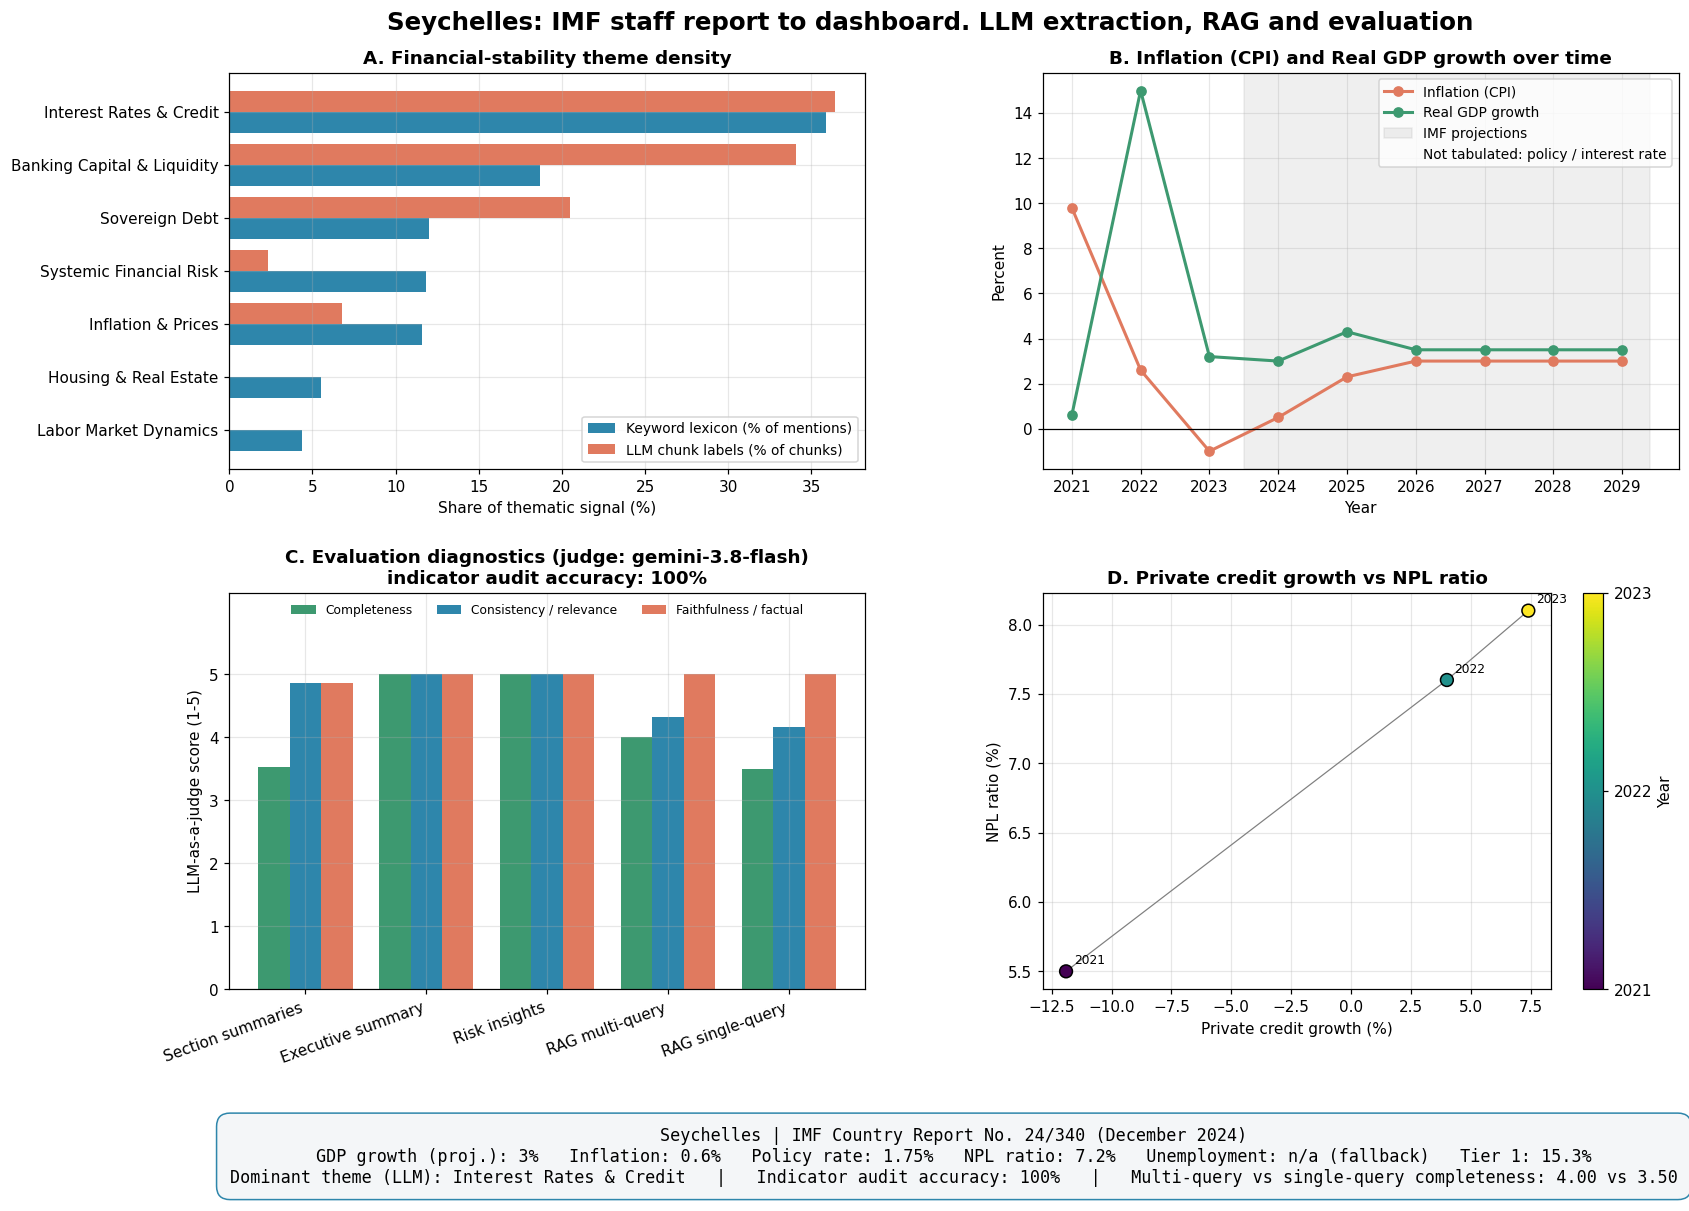

In [22]:
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 9, "figure.dpi": 110})
PALETTE = {"lex": "#2E86AB", "llm": "#E07A5F", "a": "#2E86AB", "b": "#E07A5F", "c": "#3D9970", "d": "#7F5A83"}


def pick_series(patterns: List[str]) -> Optional[pd.DataFrame]:
    for p in patterns:
        m = trend_long[trend_long.indicator.str.contains(p, case=False, regex=True)]
        if not m.empty:
            name = m.indicator.iloc[0]
            return m[m.indicator == name].sort_values("year")
    return None


def panel_themes(ax):
    d = theme_df.sort_values("lexicon_share_pct")
    y = np.arange(len(d))
    ax.barh(y - 0.2, d.lexicon_share_pct, 0.4, label="Keyword lexicon (% of mentions)", color=PALETTE["lex"])
    ax.barh(y + 0.2, d.llm_share_pct, 0.4, label="LLM chunk labels (% of chunks)", color=PALETTE["llm"])
    ax.set_yticks(y, d.theme)
    ax.set_xlabel("Share of thematic signal (%)")
    ax.set_title("A. Financial-stability theme density")
    ax.legend(loc="lower right")


def panel_trends(ax):
    lines = [("Inflation (CPI)", [r"consumer price.*average|CPI.*average|inflation.*average", r"consumer price|CPI|inflation"], PALETTE["b"]),
             ("Policy / interest rate", [r"policy rate|monetary policy rate", r"interest rate|lending rate|deposit rate"], PALETTE["a"]),
             ("Real GDP growth", [r"real GDP", r"GDP.*growth"], PALETTE["c"])]
    drawn, proj_start, drawn_labels = 0, None, []
    for label, pats, col in lines:
        s = pick_series(pats) if not trend_long.empty else None
        if s is None:
            continue
        ax.plot(s.year, s.value, marker="o", lw=2, color=col, label=label)
        drawn += 1
        drawn_labels.append(label)
        if pd.notna(s.projection_from.iloc[0]):
            proj_start = s.projection_from.iloc[0] if proj_start is None else min(proj_start, s.projection_from.iloc[0])
    if proj_start is not None:
        ax.axvspan(proj_start - 0.5, ax.get_xlim()[1], color="grey", alpha=0.12, label="IMF projections")
    missing = [label for label, pats, _ in lines if trend_long.empty or pick_series(pats) is None]
    if drawn == 0:
        ax.text(0.5, 0.5, "No verified time series extracted", ha="center", va="center", transform=ax.transAxes)
    elif missing:
        # An empty legend entry says what is absent without writing over the data.
        ax.plot([], [], " ", label="Not tabulated: " + ", ".join(m.lower() for m in missing))
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Year")
    ax.set_ylabel("Percent")
    # The title names only the series that were actually drawn.
    ax.set_title("B. " + " and ".join(drawn_labels or ["Macro trends"]) + " over time")
    ax.legend(loc="best")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))


def panel_scores(ax):
    piv = score_long.pivot(index="component", columns="metric", values="score").loc[score_wide.component]
    x = np.arange(len(piv))
    for j, (m, col) in enumerate(zip(piv.columns, [PALETTE["c"], PALETTE["a"], PALETTE["b"]])):
        ax.bar(x + (j - 1) * 0.26, piv[m], 0.26, label=m, color=col)
    ax.set_xticks(x, piv.index, rotation=20, ha="right")
    ax.set_ylim(0, 6.3)                       # head room so the legend sits above the bars
    ax.set_yticks(range(0, 6))
    ax.set_ylabel("LLM-as-a-judge score (1-5)")
    ax.set_title(f"C. Evaluation diagnostics (judge: {JUDGE.split('/')[-1]})\n"
                 f"indicator audit accuracy: {ind_accuracy:.0%}")
    ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)


def panel_relationship(ax):
    pairs = [([r"credit.*private|private.*credit"], [r"non-?performing|NPL"], "Private credit growth (%)", "NPL ratio (%)"),
             ([r"public.*debt|government.*debt|debt"], [r"primary balance", r"overall balance|fiscal balance"],
              "Public debt (% of GDP)", "Fiscal balance (% of GDP)")]
    for xp, yp, xl, yl in pairs:
        sx, sy = (pick_series(xp), pick_series(yp)) if not trend_long.empty else (None, None)
        if sx is None or sy is None:
            continue
        m = sx[["year", "value"]].merge(sy[["year", "value"]], on="year", suffixes=("_x", "_y"))
        if len(m) < 3:
            continue
        sc = ax.scatter(m.value_x, m.value_y, c=m.year, cmap="viridis", s=70, edgecolor="black", zorder=3)
        ax.plot(m.value_x, m.value_y, color="grey", lw=0.8, zorder=2)
        for _, r in m.iterrows():
            ax.annotate(str(int(r.year)), (r.value_x, r.value_y), textcoords="offset points", xytext=(5, 5), fontsize=8)
        cb = plt.colorbar(sc, ax=ax, label="Year")
        cb.set_ticks(sorted(m.year.unique()))
        cb.set_ticklabels([str(int(y)) for y in sorted(m.year.unique())])
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        ax.set_title(f"D. {xl.split(' (')[0]} vs {yl.split(' (')[0]}")
        return
    ax.boxplot([df_j.factual_alignment, df_j.completeness, df_j.consistency], tick_labels=["Factual", "Complete", "Consistent"])
    ax.set_ylabel("Section-summary judge score")
    ax.set_title("D. Spread of section-summary scores")


def exec_text() -> str:
    def fmt(f, unit="%"):
        v = core_indicators[f]
        return f"{v:g}{unit}" if v is not None else "n/a (fallback)"
    top_theme = theme_df.sort_values("llm_share_pct", ascending=False).theme.iloc[0]
    return (f"{CONFIG['country']} | {CONFIG['report_label']}\n"
            f"GDP growth (proj.): {fmt('gdp_growth_forecast_pct')}   Inflation: {fmt('headline_inflation_rate_pct')}   "
            f"Policy rate: {fmt('central_bank_policy_rate_pct')}   NPL ratio: {fmt('non_performing_loan_ratio')}   "
            f"Unemployment: {fmt('unemployment_rate_pct')}   Tier 1: {fmt('tier_1_capital_ratio')}\n"
            f"Dominant theme (LLM): {top_theme}   |   Indicator audit accuracy: {ind_accuracy:.0%}   |   "
            f"Multi-query vs single-query completeness: {rag_summary.loc['multi_query', 'completeness']:.2f} vs "
            f"{rag_summary.loc['single_query', 'completeness']:.2f}")


panels = [("fig_A_themes", panel_themes), ("fig_B_trends", panel_trends),
          ("fig_C_judge_scores", panel_scores), ("fig_D_relationship", panel_relationship)]
for name, fn in panels:
    f, ax = plt.subplots(figsize=(8, 5.2))
    fn(ax)
    f.tight_layout()
    f.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.close(f)

fig = plt.figure(figsize=(17, 12.5))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.22], hspace=0.42, wspace=0.28, top=0.93)
for (name, fn), pos in zip(panels, [gs[0, 0], gs[0, 1], gs[1, 0], gs[1, 1]]):
    fn(fig.add_subplot(pos))
tax = fig.add_subplot(gs[2, :])
tax.axis("off")
tax.text(0.5, 0.5, exec_text(), ha="center", va="center", fontsize=11, family="monospace",
         bbox=dict(boxstyle="round,pad=0.8", fc="#F4F6F8", ec="#2E86AB"))
fig.suptitle(f"{CONFIG['country']}: IMF staff report to dashboard. LLM extraction, RAG and evaluation",
             fontsize=16, fontweight="bold", y=0.975)
fig.savefig(FIG_DIR / "dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

**5. Run record**

This shows the time, tokens and cache use of each model call.

In [23]:
log_df = pd.DataFrame(CALL_LOG)
save_json(CALL_LOG, "llm_call_log.json")
if not log_df.empty:
    diag = log_df.groupby(["model", "tag"]).agg(calls=("tag", "size"), cache_hits=("cache_hit", "sum"),
                                                  mean_latency_s=("latency_s", "mean")).round(2)
    print(f"Total calls: {len(log_df)} | served from cache: {log_df.cache_hit.mean():.0%}")
    display(diag) if "display" in dir(__builtins__) or IN_COLAB else print(diag)
print("Outputs:", sorted(p.name for p in JSON_DIR.glob("*.json")))
print("Figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Total calls: 87 | served from cache: 100%


calls  cache_hits  \
model                   tag                                         
google/gemini-3.7-flash exec_revise                 1           1   
                        exec_summary                1           1   
                        indicators                  1           1   
                        insights                    1           1   
                        mq_variants                12          12   
                        rag_multi_query             6           6   
                        rag_single_query            6           6   
                        section_summary            15          15   
                        series                      3           3   
                        theme_classify             10          10   
google/gemini-3.8-flash judge_exec                  1           1   
                        judge_exec_revised          1           1   
                        judge_indicators            1           1   
                        judge_insights              1           1   
                        judge_rag_multi_query       6           6   
                        judge_rag_single_query      6           6   
                        judge_section              15          15   

                                                mean_latency_s  
model                   tag                                     
google/gemini-3.7-flash exec_revise                     160.26  
                        exec_summary                     19.68  
                        indicators                        7.91  
                        insights                         11.39  
                        mq_variants                      10.87  
                        rag_multi_query                  10.06  
                        rag_single_query                  7.87  
                        section_summary                  34.23  
                        series                           38.71  
                        theme_classify                   27.55  
google/gemini-3.8-flash judge_exec                       15.13  
                        judge_exec_revised               14.30  
                        judge_indicators                 10.09  
                        judge_insights                    9.70  
                        judge_rag_multi_query             8.29  
                        judge_rag_single_query            8.64  
                        judge_section                    11.43

Outputs: ['chunks.json', 'cleaning_stats.json', 'core_indicators.json', 'core_indicators_detailed.json', 'dashboard_data.json', 'executive_summary.json', 'executive_summary_draft.json', 'indicator_audit.json', 'llm_call_log.json', 'qualitative_insights.json', 'rag_comparison.json', 'rag_results.json', 'section_summaries.json', 'sections.json', 'summary_judgements.json', 'temporal_series.json', 'theme_distribution.json']
Figures: ['dashboard.png', 'fig_A_themes.png', 'fig_B_trends.png', 'fig_C_judge_scores.png', 'fig_D_relationship.png']
